# Projet : Algèbre Linéaire Numérique Appliquée à l’Analyse de Données

**Réalisé par :** Abdessamad Ait Brahim  
**Encadré par :** Dr.Abdel Louly  

Ce projet individuel permet de se familiariser avec l’algèbre linéaire numérique en Python, en utilisant principalement les bibliothèques numpy et scipy. Il aborde la résolution de systèmes linéaires, les décompositions matricielles (notamment SVD et QR), ainsi que leurs applications concrètes en analyse de données.

*Filière : Big Data et Intelligence Artificielle.*


# Exercice 1 : Résolution de Systèmes Linéaires

# 1.1 Méthodes Directes : Décomposition LU

In [1]:
# importer les bibliothiques essentilles
import numpy as np
from scipy.linalg import lu, solve_triangular, cho_factor, cho_solve , qr
import time
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# a. Genérer une matrice A (4x4) symétrique définie positive et un vecteur b (4x1) aleatoirement sans utiliser la parametre graine de la reproductivité


In [2]:
def generer_matrice_symetrique_definie_positive(taille):
    """
    Cette fonction accepte un paramètre :
    - taille : entier, la taille de la matrice carrée à générer.

    Elle retourne une matrice symétrique définie positive de dimensions (taille x taille).
    """
    
    # Génère une matrice aléatoire B de taille (taille x taille)
    B = np.random.randn(taille, taille)

    # A = Bᵗ * B est symétrique et semi-définie positive
    # En ajoutant la matrice identité, on garantit que A est définie positive
    A = B.T @ B + np.eye(taille)

    return A


In [3]:
def generer_vecteur_aleatoire(taille):
    """ Cette fonction génère un vecteur aléatoire de taille donnée.
    Paramètre :
    - taille : entier  — taille du vecteur.

    Retour :
    - ndarray— vecteur aéatoire . """
    return np.random.randn(taille)


In [4]:
taille = 4
A = generer_matrice_symetrique_definie_positive(taille)
b = generer_vecteur_aleatoire(taille)
print("Matrice A (4x4) symétrique définie positive (aléatoire):")
print(A)

print(f"\nVecteur b (4x1) (aléatoire):")
print(b)

Matrice A (4x4) symétrique définie positive (aléatoire):
[[ 7.77717154 -1.78987519 -2.34179586 -2.84603904]
 [-1.78987519  3.59556301  3.28294654  2.01185422]
 [-2.34179586  3.28294654  8.38198572 -0.71387036]
 [-2.84603904  2.01185422 -0.71387036  6.42079194]]

Vecteur b (4x1) (aléatoire):
[2.30934991 1.77530137 0.56494768 1.78891704]


In [5]:
# Vérification que A est symétrique et définie positive
valeurs_propres = np.linalg.eigvals(A)
est_symetrique = np.allclose(A, A.T)
est_definie_positive = np.all(valeurs_propres > 0)
nombre_condition = np.linalg.cond(A)

print(f"\nVérification:")
print(f"- Matrice symétrique: {est_symetrique}")
print(f"- Matrice définie positive: {est_definie_positive}")
print(f"- Valeurs propres: {valeurs_propres}")
print(f"- Nombre de condition: {nombre_condition:.2e}")


Vérification:
- Matrice symétrique: True
- Matrice définie positive: True
- Valeurs propres: [12.73378234  8.31293848  4.10311689  1.02567449]
- Nombre de condition: 1.24e+01


# b. Utiliser scipy.linalg.lu pour obtenir les matrices P, L, U telles que PA = LU

In [6]:
print("\nDÉCOMPOSITION LU AVEC SCIPY")
P, L, U = lu(A)

print("Matrice de permutation P:")
print(P)
print(f"\nMatrice triangulaire inférieure L:")
print(L)
print(f"\nMatrice triangulaire supérieure U:")
print(U)


DÉCOMPOSITION LU AVEC SCIPY
Matrice de permutation P:
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]

Matrice triangulaire inférieure L:
[[ 1.          0.          0.          0.        ]
 [-0.23014475  1.          0.          0.        ]
 [-0.30111151  0.86190677  1.          0.        ]
 [-0.36594783  0.42619656 -0.51589642  1.        ]]

Matrice triangulaire supérieure U:
[[ 7.77717154 -1.78987519 -2.34179586 -2.84603904]
 [ 0.          3.18363263  2.74399453  1.35685328]
 [ 0.          0.          5.31177657 -2.7403265 ]
 [ 0.          0.          0.          3.38727931]]


In [7]:
# Vérification que PA = LU
verification_PA_LU = np.allclose(P @ A, L @ U)
erreur_decomposition = np.linalg.norm(P @ A - L @ U)
print(f"\nVérification PA = LU: {verification_PA_LU}")
print(f"Erreur ||PA - LU||: {erreur_decomposition:.2e}")


Vérification PA = LU: True
Erreur ||PA - LU||: 6.66e-16


# c. Résolverle système Ax = b en utilisant les matrices L et U (résolution triangulaire)

In [8]:
print("\nRÉSOLUTION TRIANGULAIRE")
print("Système original: Ax = b")
print("Après décomposition: PAx = Pb, soit LUx = Pb")
print("\nÉtapes de résolution:")
# Étape 1: Calculer Pb
Pb = P @ b
print(f"Étape 1 - Calcul de Pb:")
print(f"Pb = P @ b = {Pb}")

# Étape 2: Résoudre Ly = Pb (substitution avant)
y = solve_triangular(L, Pb, lower=True)
print(f"\nÉtape 2 - Résolution de Ly = Pb (substitution avant):")
print(f"y = {y}")

# Étape 3: Résoudre Ux = y (substitution arrière)
x = solve_triangular(U, y, lower=False)
print(f"\nÉtape 3 - Résolution de Ux = y (substitution arrière):")
print(f"x = {x}")

print(f"\nSOLUTION FINALE avec décomposition LU:")
print(f"x = {x}")


RÉSOLUTION TRIANGULAIRE
Système original: Ax = b
Après décomposition: PAx = Pb, soit LUx = Pb

Étapes de résolution:
Étape 1 - Calcul de Pb:
Pb = P @ b = [2.30934991 1.77530137 0.56494768 1.78891704]

Étape 2 - Résolution de Ly = Pb (substitution avant):
y = [ 2.30934991  2.30678613 -0.72791507  1.27534554]

Étape 3 - Résolution de Ux = y (substitution arrière):
x = [0.57042693 0.51480625 0.05720235 0.3765103 ]

SOLUTION FINALE avec décomposition LU:
x = [0.57042693 0.51480625 0.05720235 0.3765103 ]


# d. Vérifier la solution en comparant avec numpy.linalg.solve

In [9]:
print("\nVÉRIFICATION AVEC NUMPY.LINALG.SOLVE")
# Solution avec numpy.linalg.solve
x_direct = np.linalg.solve(A, b)
print(f"Solution avec numpy.linalg.solve:")
print(f"x_direct = {x_direct}")

# Calcul de l'erreur entre la solution LU et numpy
erreur = np.linalg.norm(x - x_direct)
erreur_relative = erreur / np.linalg.norm(x_direct)

print(f"\nComparaison des solutions:")
print(f"Erreur absolue ||x_LU - x_direct|| = {erreur:.2e}")
print(f"Erreur relative = {erreur_relative:.2e}")

# Tolérances
if erreur < 1e-12:
    print("Les solutions sont identiques (à la précision machine)")
elif erreur < 1e-10:
    print("Les solutions sont très proches")
else:
    print("Différence détectable entre les solutions")

# Vérification finale avec les résidus
print("\nVérification finale - Calcul des résidus:")
residu_LU = np.linalg.norm(A @ x - b)
residu_direct = np.linalg.norm(A @ x_direct - b)

print(f"Résidu méthode LU: ||Ax - b|| = {residu_LU:.2e}")
print(f"Résidu numpy: ||Ax - b|| = {residu_direct:.2e}")



VÉRIFICATION AVEC NUMPY.LINALG.SOLVE
Solution avec numpy.linalg.solve:
x_direct = [0.57042693 0.51480625 0.05720235 0.3765103 ]

Comparaison des solutions:
Erreur absolue ||x_LU - x_direct|| = 0.00e+00
Erreur relative = 0.00e+00
Les solutions sont identiques (à la précision machine)

Vérification finale - Calcul des résidus:
Résidu méthode LU: ||Ax - b|| = 5.87e-16
Résidu numpy: ||Ax - b|| = 5.87e-16


# 1.2 Méthode de Cholesky

# a. Utiliser scipy.linalg.cho_factor et scipy.linalg.cho_solve pour résoudre Ax = b.

In [10]:
# Calcul de la factorisation de Cholesky
c, lower = cho_factor(A)  # c est la matrice factorisée, lower indique si la factorisation est inférieure

# Résolution du système
x_chol = cho_solve((c, lower), b)

print("Solution par décomposition de Cholesky :")
print(x_chol)

Solution par décomposition de Cholesky :
[0.57042693 0.51480625 0.05720235 0.3765103 ]


# b. Comparer la précision et le temps d’exécution avec la méthode LU

In [11]:
# Méthode LU
debut_lu = time.time()
P, L, U = lu(A)
Pb = P @ b
y = solve_triangular(L, Pb, lower=True)
x_lu = solve_triangular(U, y, lower=False)
fin_lu = time.time()
temps_lu = fin_lu - debut_lu

# Méthode Cholesky
debut_chol = time.time()
c, lower = cho_factor(A)
x_chol = cho_solve((c, lower), b)
fin_chol = time.time()
temps_chol = fin_chol - debut_chol

# Précision : différence entre les solutions
erreur = np.linalg.norm(x_lu - x_chol)

# Résidus
residu_lu = np.linalg.norm(A @ x_lu - b)
residu_chol = np.linalg.norm(A @ x_chol - b)

# Affichage résultats
print(f"Temps d'exécution LU : {temps_lu:.6f} s")
print(f"Temps d'exécution Cholesky : {temps_chol:.6f} s")
print(f"Erreur entre solutions LU et Cholesky : {erreur:.2e}")
print(f"Résidu méthode LU : {residu_lu:.2e}")
print(f"Résidu méthode Cholesky : {residu_chol:.2e}")

Temps d'exécution LU : 0.001004 s
Temps d'exécution Cholesky : 0.000000 s
Erreur entre solutions LU et Cholesky : 1.11e-16
Résidu méthode LU : 5.87e-16
Résidu méthode Cholesky : 5.87e-16


# 1.3 Méthodes Itératives : Jacobi et Gauss-Seidel

# a. Fonction pour la méthode de Jacobi : décomposition et itération

In [12]:
def methode_jacobi(A, b, tol=1e-6, max_iter=100):
    """
    Cette fonction résout le système Ax = b avec la méthode itérative de Jacobi.
    Paramètres : A : matrice carrée (n x n) dans notre cas (taille x taille)
    b : vecteur (n)
    tol : tolérance d'arrêt (critère de convergence)
    max_iter : nombre maximum d'itérations autorisées
    
    Retour :
    x : solution approchée
    n_iter : nombre d'itérations effectuées
    """
    n = A.shape[0]
    x = np.zeros_like(b, dtype=float)  # Initialisation de la solution (x0 = 0)
    
    D = np.diag(np.diag(A))            # Matrice diagonale D
    L_plus_U = A - D                   # Partie hors diagonale (L + U)
    
    D_inv = np.diag(1 / np.diag(D))   # Inverse de D (diagonale inversée)
    
    for k in range(max_iter):
        x_new = D_inv @ (b - L_plus_U @ x)  # Calcul de la nouvelle itération
        
        # Critère d'arrêt : si la différence max entre itérations est faible
        if np.linalg.norm(x_new - x, ord=np.inf) < tol:
            return x_new, k+1  # Convergence atteinte
        
        x = x_new
    
    return x, max_iter  # Retour si pas de convergence au bout de max_iter


# b. Fonction méthode de Gauss-Seidel

In [13]:
def methode_gauss_seidel(A, b, tol=1e-6, max_iter=100):
    """
    cette fésout le système Ax = b avec la méthode itérative de Gauss-Seidel.
    
    Paramètres :
    -------------
    A : matrice carrée (n x n)
    b : vecteur (n)
    tol : tolérance d'arrêt
    max_iter : nombre max d'itérations
    
    Retour :
    --------
    x : solution approchée
    n_iter : nombre d'itérations effectuées
    """
    n = A.shape[0]
    x = np.zeros_like(b, dtype=float)  # Initialisation
    
    for k in range(max_iter):
        x_new = np.copy(x) #nouvelle version de x ....
        for i in range(n):
            somme = 0
            for j in range(n):
                if j != i:
                    # Utilise la dernière valeur connue pour la mise à jour
                    somme += A[i, j] * (x_new[j] if j < i else x[j])
            x_new[i] = (b[i] - somme) / A[i, i]
        
        # Critère d'arrêt : différence max entre itérations
        if np.linalg.norm(x_new - x, ord=np.inf) < tol:
            return x_new, k+1  # Convergence
        
        x = x_new
    
    return x, max_iter  # Pas de convergence après max_iter


# c. Tester les deux méthodes sur le système Ax = b avec une tolérance de 10−6 et un maximum de 100 itérations.

In [14]:
tol = 1e-6
max_iter = 100

# Résolution par Jacobi
x_jacobi, iter_jacobi = methode_jacobi(A, b, tol, max_iter)

# Résolution par Gauss-Seidel
x_gs, iter_gs = methode_gauss_seidel(A, b, tol, max_iter)

print("Résultats méthode Jacobi :")
print(f"Solution x = {x_jacobi}")
print(f"Nombre d'itérations = {iter_jacobi}")

print("\nRésultats méthode Gauss-Seidel :")
print(f"Solution x = {x_gs}")
print(f"Nombre d'itérations = {iter_gs}")

Résultats méthode Jacobi :
Solution x = [ 0.72054657  0.2450207  -0.07738835  0.24195657]
Nombre d'itérations = 100

Résultats méthode Gauss-Seidel :
Solution x = [0.57042681 0.51480738 0.05720181 0.37650983]
Nombre d'itérations = 29


# d. Comparer le nombre d’itérations et la précision.

In [15]:
# Solution exacte avec numpy.linalg.solve pour comparer
x_exact = np.linalg.solve(A, b)

# Calcul des erreurs entre solutions approchées et solution exacte
erreur_jacobi = np.linalg.norm(x_jacobi - x_exact)
erreur_gs = np.linalg.norm(x_gs - x_exact)

print("\nComparaison de la précision :")
print(f"Erreur Jacobi par rapport à la solution exacte : {erreur_jacobi:.2e}")
print(f"Erreur Gauss-Seidel par rapport à la solution exacte : {erreur_gs:.2e}")

print("\nConclusion :")
if iter_gs < iter_jacobi:
    print(f"Gauss-Seidel converge plus rapidement ({iter_gs} itérations) que Jacobi ({iter_jacobi} itérations).")
else:
    print(f"Jacobi converge plus rapidement ({iter_jacobi} itérations) que Gauss-Seidel ({iter_gs} itérations).")

if erreur_gs < erreur_jacobi:
    print("Gauss-Seidel fournit une solution plus précise.")
else:
    print("Jacobi fournit une solution plus précise.")



Comparaison de la précision :
Erreur Jacobi par rapport à la solution exacte : 3.63e-01
Erreur Gauss-Seidel par rapport à la solution exacte : 1.34e-06

Conclusion :
Gauss-Seidel converge plus rapidement (29 itérations) que Jacobi (100 itérations).
Gauss-Seidel fournit une solution plus précise.


# Exercice 2 : Décompositions SVD et QR


# 2.1 Décomposition SVD

# a. Créez une matrice de données D (10x5)

In [16]:
# Simulation de données : ventes hebdomadaires (en unités) dans 10 magasins pour 5 produits
D = np.random.randint(50, 500, size=(10, 5))

print("Matrice de données D (10 magasins × 5 produits) :")
print(D)


Matrice de données D (10 magasins × 5 produits) :
[[281 119  84  65 236]
 [105 281 290  89  76]
 [400 361 476 181 128]
 [452 469 205 301 437]
 [389 215 471 390 422]
 [478 344 349 350 402]
 [221 406 461 470 219]
 [350 279 329  65 296]
 [210 407  77 191  72]
 [317  66 415  56 332]]


# b. Utiliser numpy.linalg.svd pour obtenir U, S, V

In [17]:
# Décomposition SVD
U, S, Vt = np.linalg.svd(D, full_matrices=False)

print("\nMatrice U (10x5) :")
print(U)

print("\nValeurs singulières S (vecteur) :")
print(S)

print("\nMatrice V transposée (Vᵗ) (5x5) :")
print(Vt)



Matrice U (10x5) :
[[-0.17049697  0.2082072  -0.3588655   0.06620477 -0.16363823]
 [-0.18418402 -0.19930083  0.29866883  0.30936794  0.50717889]
 [-0.34171019 -0.07450919  0.33351196  0.50280959 -0.60138039]
 [-0.39553027 -0.14367068 -0.56858346 -0.04285862  0.28672857]
 [-0.40122693  0.2528314   0.15765875 -0.47881572 -0.08495459]
 [-0.41039068  0.05928514 -0.20831522 -0.18488361 -0.3000858 ]
 [-0.37311536 -0.39768784  0.42836001 -0.40065299  0.15554248]
 [-0.2910262   0.20094362 -0.0697374   0.39981031  0.31815354]
 [-0.20268333 -0.5287123  -0.23930008  0.20639035 -0.09657729]
 [-0.26344177  0.58756018  0.18336697  0.13725717  0.20027325]]

Valeurs singulières S (vecteur) :
[2095.15693597  473.34865935  411.66924581  325.1511826   135.64144218]

Matrice V transposée (Vᵗ) (5x5) :
[[-0.49893587 -0.44908546 -0.49464832 -0.36094683 -0.41764299]
 [ 0.26871265 -0.70256527  0.25446441 -0.38769293  0.46812136]
 [-0.37211318 -0.17889645  0.80748843  0.10302545 -0.40850463]
 [ 0.29662211  0.4

# c. Reconstruiser la matrice D et vérifiez l’exactitude

In [18]:
# Conversion de S en matrice diagonale
Sigma = np.diag(S)

# Reconstruction de D
D_reconstruite = U @ Sigma @ Vt

print("\nMatrice D reconstruite à partir de U, S, Vᵗ :")
print(np.round(D_reconstruite))

# Vérification d’exactitude
erreur_reconstruction = np.linalg.norm(D - D_reconstruite)
print(f"\nErreur de reconstruction ||D - UΣVᵗ|| = {erreur_reconstruction:.2e}")



Matrice D reconstruite à partir de U, S, Vᵗ :
[[281. 119.  84.  65. 236.]
 [105. 281. 290.  89.  76.]
 [400. 361. 476. 181. 128.]
 [452. 469. 205. 301. 437.]
 [389. 215. 471. 390. 422.]
 [478. 344. 349. 350. 402.]
 [221. 406. 461. 470. 219.]
 [350. 279. 329.  65. 296.]
 [210. 407.  77. 191.  72.]
 [317.  66. 415.  56. 332.]]

Erreur de reconstruction ||D - UΣVᵗ|| = 7.92e-13


# d. Réduction de dimension : approximation avec les 2 premières valeurs singulières

In [19]:
# Réduction de dimension : k = 2
k = 2
U_k = U[:, :k]       # (10x2)
S_k = np.diag(S[:k]) # (2x2)
Vt_k = Vt[:k, :]     # (2x5)

# Approximation de D avec k=2 composantes principales
D_approx = U_k @ S_k @ Vt_k

print("\nMatrice D approximée avec les 2 premières valeurs singulières :")
print(np.round(D_approx))

# Vérification de l’erreur d’approximation
erreur_approx = np.linalg.norm(D - D_approx)
print(f"\nErreur d’approximation ||D - D_approx|| = {erreur_approx:.2e}")



Matrice D approximée avec les 2 premières valeurs singulières :
[[205.  91. 202.  91. 195.]
 [167. 240. 167. 176. 117.]
 [348. 346. 345. 272. 282.]
 [395. 420. 393. 325. 314.]
 [452. 293. 446. 257. 407.]
 [437. 366. 432. 299. 372.]
 [339. 483. 339. 355. 238.]
 [330. 207. 326. 183. 299.]
 [145. 367. 146. 250.  60.]
 [350.  52. 344.  91. 361.]]

Erreur d’approximation ||D - D_approx|| = 5.42e+02


# 2.2 Décomposition QR


# a. Utiliser scipy.linalg.qr pour décomposer la matrice D en Q et R

In [20]:
# Décomposition QR
Q, R = qr(D, mode='economic')

print("\nMatrice Q (orthogonale) :")
print(Q)

print("\nMatrice R (triangulaire supérieure) :")
print(R)



Matrice Q (orthogonale) :
[[-0.262031    0.24851777  0.31501744  0.0360352   0.03753123]
 [-0.09791194 -0.41452501 -0.32938047  0.36008777 -0.31018408]
 [-0.37299787 -0.05724897 -0.21812714  0.34370064  0.73478509]
 [-0.42148759 -0.19569229  0.46596288 -0.06657833 -0.38330327]
 [-0.36274043  0.23621384 -0.27987172 -0.46622339 -0.05634533]
 [-0.44573245  0.11905808  0.16195177 -0.26967735  0.16660556]
 [-0.20608132 -0.4746941  -0.45330444 -0.43341815 -0.06662628]
 [-0.32637314  0.02900754 -0.02342065  0.44977982 -0.2842474 ]
 [-0.19582388 -0.49656028  0.32513242  0.07084377  0.18481579]
 [-0.29560081  0.42674955 -0.33357245  0.24741323 -0.25538595]]

Matrice R (triangulaire supérieure) :
[[-1072.39218572  -896.28310687  -980.90140343  -689.63016501
   -887.45238232]
 [    0.          -466.17978543   -84.32077888  -248.37656357
     92.40121465]
 [    0.             0.          -482.73951879  -131.68695647
    -21.52725164]
 [    0.             0.             0.          -346.73889841
 

# b. Vérifier que Q est orthogonale (QᵗQ = I) et que QR = D

In [21]:
# Vérification 1 : Q est orthogonale ↔ Qᵗ @ Q = I
QTQ = Q.T @ Q
identite = np.eye(Q.shape[1])
erreur_orthogonalite = np.linalg.norm(QTQ - identite)

print("\nVérification Qᵗ @ Q = I :")
print(QTQ)
print(f"Erreur ||QᵗQ - I|| = {erreur_orthogonalite:.2e}")

# Vérification 2 : QR = D
D_reconstruit = Q @ R
erreur_reconstruction = np.linalg.norm(D - D_reconstruit)

print("\nVérification QR = D :")
print(np.round(D_reconstruit))
print(f"Erreur de reconstruction ||QR - D|| = {erreur_reconstruction:.2e}")



Vérification Qᵗ @ Q = I :
[[ 1.00000000e+00  9.71445147e-17  1.66533454e-16  0.00000000e+00
   0.00000000e+00]
 [ 9.71445147e-17  1.00000000e+00 -1.94289029e-16  6.93889390e-17
  -9.71445147e-17]
 [ 1.66533454e-16 -1.94289029e-16  1.00000000e+00  8.32667268e-17
   1.80411242e-16]
 [ 0.00000000e+00  6.93889390e-17  8.32667268e-17  1.00000000e+00
  -1.24900090e-16]
 [ 0.00000000e+00 -9.71445147e-17  1.80411242e-16 -1.24900090e-16
   1.00000000e+00]]
Erreur ||QᵗQ - I|| = 1.11e-15

Vérification QR = D :
[[281. 119.  84.  65. 236.]
 [105. 281. 290.  89.  76.]
 [400. 361. 476. 181. 128.]
 [452. 469. 205. 301. 437.]
 [389. 215. 471. 390. 422.]
 [478. 344. 349. 350. 402.]
 [221. 406. 461. 470. 219.]
 [350. 279. 329.  65. 296.]
 [210. 407.  77. 191.  72.]
 [317.  66. 415.  56. 332.]]
Erreur de reconstruction ||QR - D|| = 4.26e-13


# Exercice 3 : Application à l’Analyse de Données

# 3.1 Analyse en Composantes Principales (ACP)

# a. Centrer les données (soustraire la moyenne de chaque colonne)

In [22]:
# Centrage des données : soustraction de la moyenne colonne par colonne
D_moy = D.mean(axis=0)
D_centree = D - D_moy

print("Moyenne de chaque colonne :")
print(D_moy)

print("\nDonnées centrées :")
print(D_centree)


Moyenne de chaque colonne :
[320.3 294.7 315.7 215.8 262. ]

Données centrées :
[[ -39.3 -175.7 -231.7 -150.8  -26. ]
 [-215.3  -13.7  -25.7 -126.8 -186. ]
 [  79.7   66.3  160.3  -34.8 -134. ]
 [ 131.7  174.3 -110.7   85.2  175. ]
 [  68.7  -79.7  155.3  174.2  160. ]
 [ 157.7   49.3   33.3  134.2  140. ]
 [ -99.3  111.3  145.3  254.2  -43. ]
 [  29.7  -15.7   13.3 -150.8   34. ]
 [-110.3  112.3 -238.7  -24.8 -190. ]
 [  -3.3 -228.7   99.3 -159.8   70. ]]


# b. appliquez la SVD sur la matrice centrée

In [23]:
# Décomposition SVD de la matrice centrée
U, S, Vt = np.linalg.svd(D_centree, full_matrices=False)

print("\nValeurs singulières :")
print(S)
print("\nPremières composantes principales (lignes de Vt) :")
print(Vt)



Valeurs singulières :
[625.2127232  472.81961504 411.22673333 253.37960751 127.9605825 ]

Premières composantes principales (lignes de Vt) :
[[ 0.39387533  0.2148455   0.45179135  0.60565561  0.47725202]
 [ 0.25865509 -0.70123577  0.23094791 -0.43954902  0.4413906 ]
 [-0.37181721 -0.17352603  0.80185894  0.0455857  -0.4319547 ]
 [-0.55349448 -0.50146196 -0.27346388  0.56102695  0.22944725]
 [-0.57736955  0.42489343  0.15744009 -0.35092542  0.58152725]]


# c. Projeter les données sur les deux premières composantes principales

In [24]:
# Projection sur les 2 premières composantes principales
# U[:, :2] * S[:2] donne les coordonnées projetées
X_proj = U[:, :2] * S[:2]

print("\nDonnées projetées sur les 2 premières composantes principales :")
print(X_proj)



Données projetées sur les 2 premières composantes principales :
[[-261.64912987  114.33918521]
 [-264.92178653  -78.38070803]
 [  33.02968737  -32.70620454]
 [ 174.42861122  -73.93267528]
 [ 261.9647762   103.57736302]
 [ 235.84494045   16.71675521]
 [ 183.88158761 -200.88841647]
 [ -60.77244998  103.05433725]
 [-232.85803698 -235.36909803]
 [ -68.94819949  283.58946167]]


# d. Visualiser les données projetées avec matplotlib

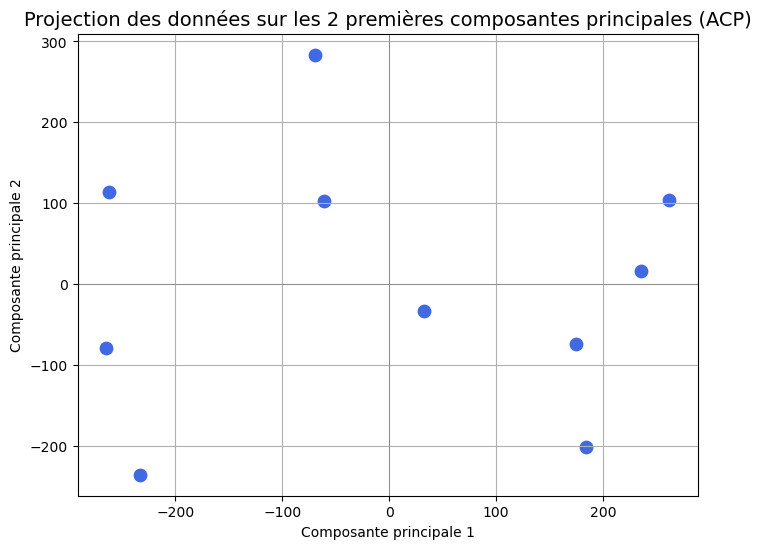

In [25]:
plt.figure(figsize=(8, 6))
plt.scatter(X_proj[:, 0], X_proj[:, 1], color='royalblue', s=80)

plt.title("Projection des données sur les 2 premières composantes principales (ACP)", fontsize=14)
plt.xlabel("Composante principale 1")
plt.ylabel("Composante principale 2")
plt.grid(True)
plt.axhline(0, color='gray', linewidth=0.5)
plt.axvline(0, color='gray', linewidth=0.5)
plt.show()


# 3.2 Compression d’Image

# a. Charger une image  et la convertir en niveaux de gris :

Image chargée - Dimensions : (1024, 781, 3)
Image convertie en niveaux de gris


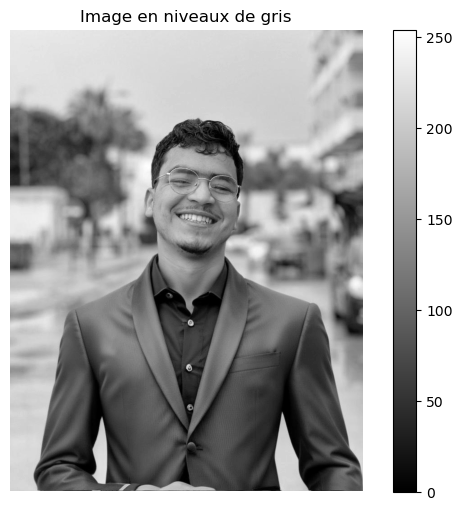

Dimensions finales : (1024, 781)
Valeurs min/max : 0.000 / 254.017


In [26]:
def charger_et_convertir_en_gris(chemin_fichier):
    """Charge une image locale et la convertit en niveaux de gris"""
    # Charger l'image
    img = mpimg.imread(chemin_fichier)
    print(f"Image chargée - Dimensions : {img.shape}")
    
    # Convertir en niveaux de gris si nécessaire
    if len(img.shape) == 3:  # Image couleur (RGB)
        gris_img = 0.299*img[:,:,0] + 0.587*img[:,:,1] + 0.114*img[:,:,2]
        print("Image convertie en niveaux de gris")
    else:  # Déjà en niveaux de gris
        gris_img = img
        print("Image déjà en niveaux de gris")
    
    return gris_img

# Utilisation
chemin_image = "../images/samad.png""
image_gris = charger_et_convertir_en_gris(chemin_image)

# Affichage
plt.figure(figsize=(8, 6))
plt.imshow(image_gris, cmap='gray')
plt.title('Image en niveaux de gris')
plt.axis('off')
plt.colorbar()
plt.show()

print(f"Dimensions finales : {image_gris.shape}")
print(f"Valeurs min/max : {image_gris.min():.3f} / {image_gris.max():.3f}")


# b. Appliquer la SVD sur la matrice de l’image

In [27]:
def appliquer_svd(image):
    """Applique la décomposition en valeurs singulières (SVD) sur l'image"""
    print("Application de la SVD...")
    
    # SVD : A = U × Σ × V^T
    U, valeurs_singulieres, Vt = np.linalg.svd(image, full_matrices=False)
    
    print(f"Dimensions de U : {U.shape}")
    print(f"Nombre de valeurs singulières : {len(valeurs_singulieres)}")
    print(f"Dimensions de Vt : {Vt.shape}")
    
    return U, valeurs_singulieres, Vt


In [28]:
# Application de la SVD
U, s, Vt = appliquer_svd(image_gris)


Application de la SVD...
Dimensions de U : (1024, 781)
Nombre de valeurs singulières : 781
Dimensions de Vt : (781, 781)


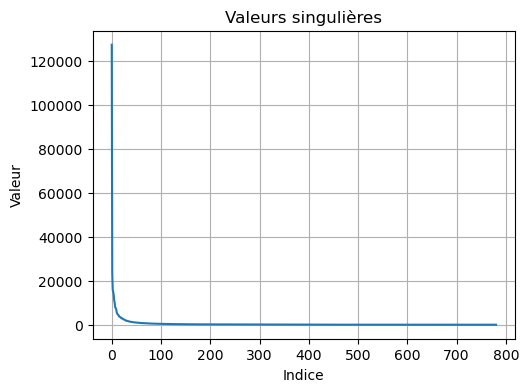

In [29]:
# Visualisation des valeurs singulières
plt.figure(figsize=(12, 4))

# Graphique 1 : Valeurs singulières
plt.subplot(1, 2, 1)
plt.plot(s)
plt.title('Valeurs singulières')
plt.xlabel('Indice')
plt.ylabel('Valeur')
plt.grid(True)


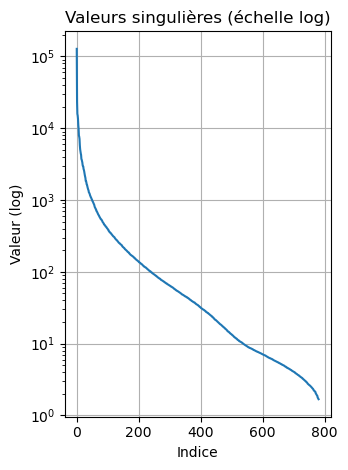

In [30]:
# Graphique 2 : Valeurs singulières en échelle logarithmique
plt.subplot(1, 2, 2)
plt.semilogy(s)
plt.title('Valeurs singulières (échelle log)')
plt.xlabel('Indice')
plt.ylabel('Valeur (log)')

plt.grid(True)

plt.tight_layout()
plt.show()


In [31]:
# Informations sur la SVD
print(f"\nInformations SVD:")
print(f"Rang de la matrice: {np.sum(s > 1e-10)}")
print(f"Plus grande valeur singulière: {s[0]:.2f}")
print(f"Plus petite valeur singulière: {s[-1]:.2e}")
print(f"Rapport max/min: {s[0]/s[-1]:.2e}")


Informations SVD:
Rang de la matrice: 781
Plus grande valeur singulière: 127457.12
Plus petite valeur singulière: 1.68e+00
Rapport max/min: 7.57e+04


# c. Reconstruire l’image avec différents rangs (k = 10, 50, 100)

In [32]:
def reconstruire_image(U, s, Vt, rang):
    """Reconstruit l'image en utilisant seulement les 'rang' premières composantes"""
    print(f"Reconstruction avec rang {rang}...")
    
    # Sélectionner seulement les 'rang' premières composantes
    U_tronque = U[:, :rang]
    s_tronque = s[:rang]
    Vt_tronque = Vt[:rang, :]
    
    # Reconstruction : A_approx = U_k × Σ_k × V_k^T
    reconstruite = U_tronque @ np.diag(s_tronque) @ Vt_tronque
    
    return reconstruite

def calculer_taux_compression(shape_original, rang):
    """Calcule le taux de compression en pourcentage"""
    m, n = shape_original
    taille_originale = m * n
    taille_compressee = rang * (m + n + 1)  # U_k + s_k + Vt_k
    taux = (taille_compressee / taille_originale) * 100
    return taux

# Différents rangs à tester
rangs = [10, 50, 100]
images_reconstruites = {}

# Remplacer 'image_gris' par le nom exact de ta variable d'image en niveaux de gris
for rang in rangs:
    images_reconstruites[rang] = reconstruire_image(U, s, Vt, rang)
    taux_compression = calculer_taux_compression(image_gris.shape, rang)
    print(f"Rang {rang} : {taux_compression:.1f}% de la taille originale")

print(f"\nErreurs de reconstruction (norme de Frobenius) :")
for rang in rangs:
    erreur = np.linalg.norm(image_gris - images_reconstruites[rang], 'fro')
    erreur_relative = erreur / np.linalg.norm(image_gris, 'fro') * 100
    print(f"Rang {rang} : {erreur_relative:.2f}% d'erreur relative")

print(f"\nImages reconstruites stockées dans 'images_reconstruites'")
print(f"Rangs disponibles : {list(images_reconstruites.keys())}")


Reconstruction avec rang 10...
Rang 10 : 2.3% de la taille originale
Reconstruction avec rang 50...
Rang 50 : 11.3% de la taille originale
Reconstruction avec rang 100...
Rang 100 : 22.6% de la taille originale

Erreurs de reconstruction (norme de Frobenius) :
Rang 10 : 12.94% d'erreur relative
Rang 50 : 3.91% d'erreur relative
Rang 100 : 2.00% d'erreur relative

Images reconstruites stockées dans 'images_reconstruites'
Rangs disponibles : [10, 50, 100]


# d. Visualiser les résultats 

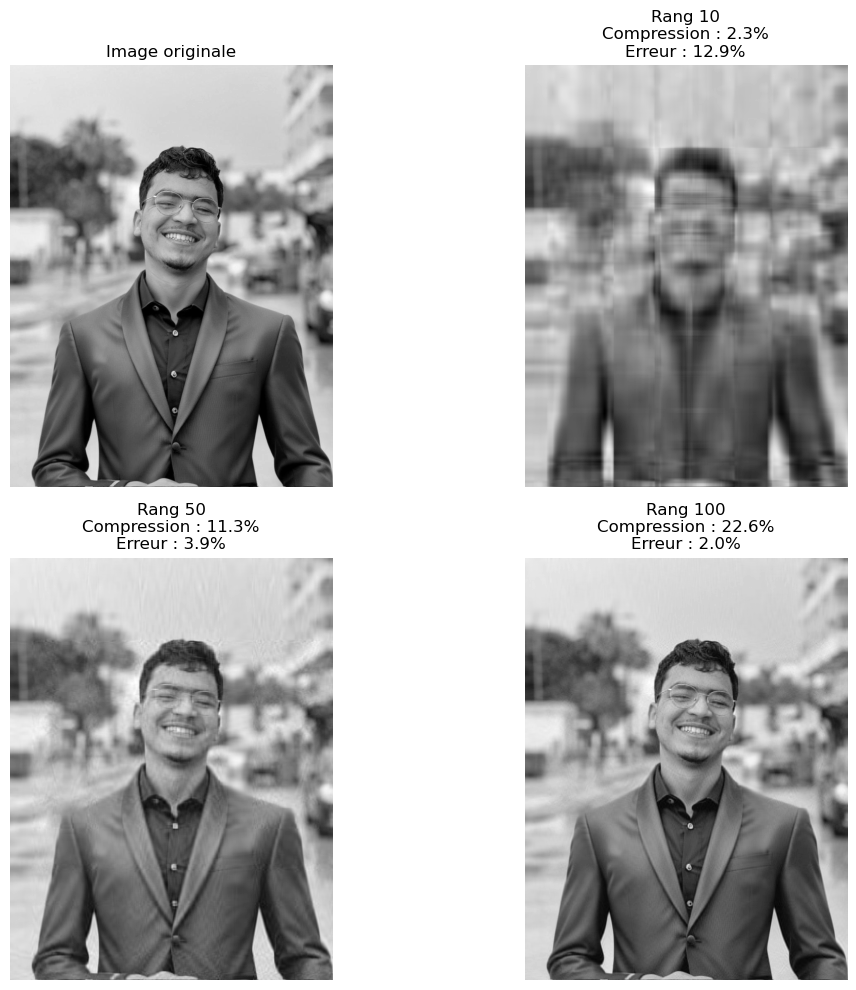

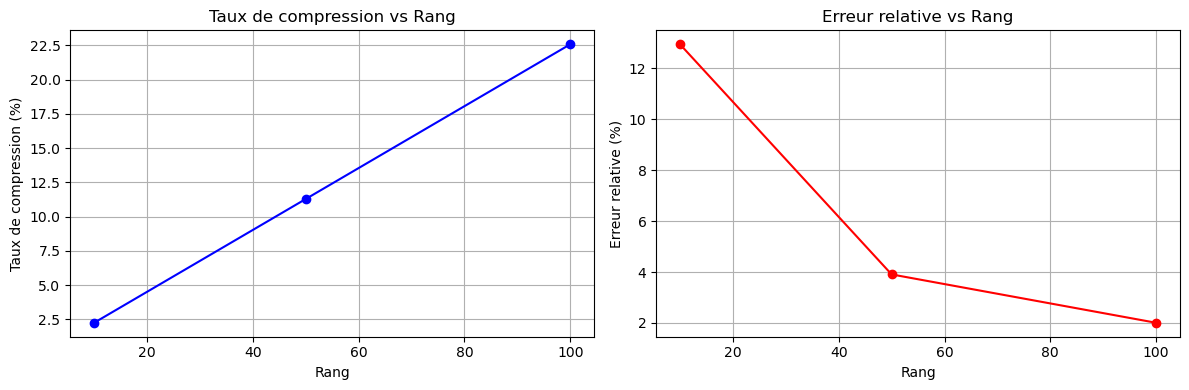


TABLEAU RÉCAPITULATIF DE LA COMPRESSION
Rang     Compression (%)    Erreur (%)      Qualité   
------------------------------------------------------------
10       2.3                12.9            Bonne     
50       11.3               3.9             Excellente
100      22.6               2.0             Excellente


In [33]:
def visualiser_resultats_compression(image_gris, images_reconstruites, rangs):
    """Affiche l’image originale et les reconstructions aux différents rangs"""
    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    
    axes[0, 0].imshow(image_gris, cmap='gray')
    axes[0, 0].set_title('Image originale')
    axes[0, 0].axis('off')
    
    positions = [(0, 1), (1, 0), (1, 1)]
    for i, rang in enumerate(rangs):
        r, c = positions[i]
        img = images_reconstruites[rang]
        
        taux = (rang * (image_gris.shape[0] + image_gris.shape[1] + 1)) / (image_gris.size) * 100
        erreur = np.linalg.norm(image_gris - img, 'fro')
        erreur_rel = erreur / np.linalg.norm(image_gris, 'fro') * 100
        
        axes[r, c].imshow(img, cmap='gray')
        axes[r, c].set_title(f'Rang {rang}\nCompression : {taux:.1f}%\nErreur : {erreur_rel:.1f}%')
        axes[r, c].axis('off')
    
    plt.tight_layout()
    plt.show()

def tracer_analyse_compression(image_gris, images_reconstruites, rangs):
    """Trace les courbes taux de compression et erreur relative selon rang"""
    taux_compression = []
    erreurs_relatives = []
    
    for rang in rangs:
        taux = (rang * (image_gris.shape[0] + image_gris.shape[1] + 1)) / (image_gris.size) * 100
        taux_compression.append(taux)
        
        erreur = np.linalg.norm(image_gris - images_reconstruites[rang], 'fro')
        erreurs_relatives.append(erreur / np.linalg.norm(image_gris, 'fro') * 100)
    
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    
    axes[0].plot(rangs, taux_compression, 'bo-')
    axes[0].set_xlabel('Rang')
    axes[0].set_ylabel('Taux de compression (%)')
    axes[0].set_title('Taux de compression vs Rang')
    axes[0].grid(True)
    
    axes[1].plot(rangs, erreurs_relatives, 'ro-')
    axes[1].set_xlabel('Rang')
    axes[1].set_ylabel('Erreur relative (%)')
    axes[1].set_title('Erreur relative vs Rang')
    axes[1].grid(True)
    
    plt.tight_layout()
    plt.show()

def afficher_tableau_recapitulatif(image_gris, images_reconstruites, rangs):
    """Affiche un tableau avec rang, compression, erreur et qualité"""
    print("\n" + "="*60)
    print("TABLEAU RÉCAPITULATIF DE LA COMPRESSION")
    print("="*60)
    print(f"{'Rang':<8} {'Compression (%)':<18} {'Erreur (%)':<15} {'Qualité':<10}")
    print("-"*60)
    
    for rang in rangs:
        taux = (rang * (image_gris.shape[0] + image_gris.shape[1] + 1)) / (image_gris.size) * 100
        erreur = np.linalg.norm(image_gris - images_reconstruites[rang], 'fro')
        erreur_rel = erreur / np.linalg.norm(image_gris, 'fro') * 100
        
        if erreur_rel < 5:
            qualite = "Excellente"
        elif erreur_rel < 15:
            qualite = "Bonne"
        elif erreur_rel < 30:
            qualite = "Moyenne"
        else:
            qualite = "Faible"
        
        print(f"{rang:<8} {taux:<18.1f} {erreur_rel:<15.1f} {qualite:<10}")

#APPLICATION
rangs = [10, 50, 100]

visualiser_resultats_compression(image_gris, images_reconstruites, rangs)
tracer_analyse_compression(image_gris, images_reconstruites, rangs)
afficher_tableau_recapitulatif(image_gris, images_reconstruites, rangs)
